# Brusselator order convergence


## 1. Setup


In [1]:
from pathlib import Path
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from pinns.brusselator import BrusselatorPINN, brusselator_residual
from pinns.brusselator_spectral import (
    solve_brusselator_spectral,
    brusselator_spectral_residual,
)


In [2]:
SEED = 42
DEVICE = torch.device("cpu")
DTYPE = torch.float64

torch.set_num_threads(1)


## 2. Problem and points


In [3]:
INTERIOR_POINTS = 2048
EVAL_GRID_SIZE = 65
PARAMETERS = {"a": 1.0, "b": 3.0, "du": 0.03, "dv": 0.02}

axis = torch.linspace(-1, 1, EVAL_GRID_SIZE, dtype=DTYPE, device=DEVICE)[1:-1]
eval_points = torch.cartesian_prod(axis, axis)


def collocation_points(sampling, seed):
    if sampling == "sobol":
        engine = torch.quasirandom.SobolEngine(dimension=2, scramble=True, seed=seed)
        return (2 * engine.draw(INTERIOR_POINTS) - 1).to(dtype=DTYPE, device=DEVICE)
    # Tensor-product Chebyshev Gauss points; keep the original fixed-size subset.
    side = math.ceil(math.sqrt(INTERIOR_POINTS))
    indices = torch.arange(side, dtype=DTYPE, device=DEVICE)
    nodes = torch.cos(torch.pi * (2 * indices + 1) / (2 * side))
    points = torch.cartesian_prod(nodes, nodes)
    selection = torch.linspace(
        0, len(points) - 1, INTERIOR_POINTS, dtype=DTYPE, device=DEVICE
    ).long()
    return points[selection]


## 3. Training schedules


In [4]:
def train_degree(degree, sampling, alternating):
    torch.manual_seed(SEED + degree)
    model = BrusselatorPINN(degree, PARAMETERS, dtype=DTYPE).to(DEVICE)
    points = collocation_points(sampling, SEED + degree)
    cycles = 5 if alternating else 1
    adam_epochs = 400 if alternating else 2000
    lbfgs_iterations = 40 if alternating else 80

    def loss():
        residual = brusselator_residual(model, points, PARAMETERS)
        return residual.square().mean(dim=0).sum()

    for _ in range(cycles):
        adam = torch.optim.Adam(model.parameters(), lr=0.001)
        for _ in range(adam_epochs):
            adam.zero_grad()
            objective = loss()
            objective.backward()
            adam.step()

        lbfgs = torch.optim.LBFGS(
            model.parameters(),
            lr=1.0,
            max_iter=lbfgs_iterations,
            max_eval=lbfgs_iterations,
            tolerance_grad=1e-9,
            tolerance_change=1e-11,
            history_size=100,
            line_search_fn="strong_wolfe",
        )

        def closure():
            lbfgs.zero_grad()
            objective = loss()
            objective.backward()
            return objective

        lbfgs.step(closure)

    # Evaluate the final model; the evaluation grid never selects weights.
    model.eval()
    residual = brusselator_residual(model, eval_points, PARAMETERS)
    mse = residual.square().mean(dim=0).sum().item()
    if not math.isfinite(mse):
        raise FloatingPointError("The evaluated PDE loss is non-finite.")
    return mse


## 4. Run the order sweep


In [5]:
DEGREES = list(range(2, 21, 2))

chebyshev_alternating = []
sobol_alternating = []
chebyshev_sequential = []
sobol_sequential = []
spectral_mse = []
spectral_converged = []

for degree in DEGREES:
    print(f"Training degree {degree}", flush=True)
    chebyshev_alternating.append(train_degree(degree, "chebyshev", alternating=True))
    sobol_alternating.append(train_degree(degree, "sobol", alternating=True))
    chebyshev_sequential.append(train_degree(degree, "chebyshev", alternating=False))
    sobol_sequential.append(train_degree(degree, "sobol", alternating=False))

    solution = solve_brusselator_spectral(degree, PARAMETERS, max_nfev=300)
    residual = brusselator_spectral_residual(solution, eval_points, PARAMETERS)
    spectral_mse.append(residual.square().mean(dim=0).sum().item())
    spectral_converged.append(solution["success"])
    print(
        f"Degree {degree}: spectral converged={solution['success']}, nfev={solution['nfev']}",
        flush=True,
    )
    if not solution["success"]:
        print(solution["message"], flush=True)


Training degree 2


Degree 2: spectral converged=True, nfev=5


Training degree 4


Degree 4: spectral converged=True, nfev=6


Training degree 6


Degree 6: spectral converged=True, nfev=5


... (10 outputs left out)

Training degree 18


Degree 18: spectral converged=True, nfev=5


Training degree 20


Degree 20: spectral converged=True, nfev=5


## 5. Order convergence


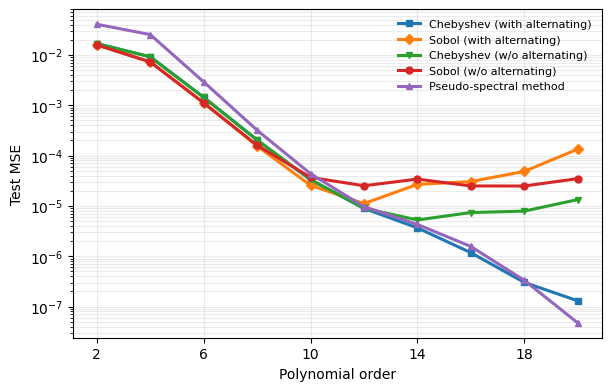

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.8), constrained_layout=True)
ax.semilogy(
    DEGREES,
    chebyshev_alternating,
    "s-",
    linewidth=2.2,
    markersize=5,
    label="Chebyshev (with alternating)",
)
ax.semilogy(
    DEGREES,
    sobol_alternating,
    "D-",
    linewidth=2.2,
    markersize=5,
    label="Sobol (with alternating)",
)
ax.semilogy(
    DEGREES,
    chebyshev_sequential,
    "v-",
    linewidth=2.2,
    markersize=5,
    label="Chebyshev (w/o alternating)",
)
ax.semilogy(
    DEGREES,
    sobol_sequential,
    "o-",
    linewidth=2.2,
    markersize=5,
    label="Sobol (w/o alternating)",
)
ax.semilogy(
    DEGREES,
    np.where(spectral_converged, spectral_mse, np.nan),
    "^-",
    linewidth=2.2,
    markersize=5,
    label="Pseudo-spectral method",
)
ax.set(xlabel="Polynomial order", ylabel="Test MSE")
ax.set_xticks([2, 6, 10, 14, 18])
ax.grid(True, which="both", alpha=0.25)
ax.legend(fontsize=8, frameon=False)
plt.show()
